# UTS Machine Learning — Klasifikasi Penyakit Ginjal Kronis (Jalur A)

- **Nama / NIM / Kelas:** Aril / 2301010390 / XX
- **Dosen:** Dr. I Gede Totok Suryawan, S.Kom., M.T.
- **Dataset:** Chronic Kidney Disease (400 pasien, 24 fitur, target `classification`)
- **Jalur:** A — Klasifikasi. Algoritma utama **KNN** dibandingkan dengan **DummyClassifier**; **SVM** sebagai algoritma kedua (nilai tambah)
- **Alur:** CRISP-DM (6 tahap), `SEED = 390`

In [1]:
# Pustaka yang dipakai (semuanya sudah tersedia di Google Colab)
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, accuracy_score,
                             precision_score, recall_score, f1_score, classification_report)

warnings.filterwarnings("ignore")

SEED = 390  # tiga digit terakhir NIM 2301010390; dipakai di semua split, CV, dan model ber-random_state
np.random.seed(SEED)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)
WARNA = {0: "#4C78A8", 1: "#E45756"}  # 0 = notckd (biru), 1 = ckd (merah)

In [2]:
# Memuat data. Urutan pencarian: folder notebook/data di repository -> folder kerja Colab -> unggah manual.
KANDIDAT = ["kidney_disease.csv", "data/kidney_disease.csv", "../data/kidney_disease.csv"]
path = next((p for p in KANDIDAT if os.path.exists(p)), None)
if path is None:
    from google.colab import files           # hanya ada di Colab
    unggahan = files.upload()                  # pilih file kidney_disease.csv
    path = list(unggahan.keys())[0]

df_raw = pd.read_csv(path)
print("Berkas:", path, "| bentuk data:", df_raw.shape)
df_raw.head()

Berkas: kidney_disease.csv | bentuk data: (400, 26)


,id,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,bu,sc,sod,pot,hemo,pcv,wc,rc,htn,dm,cad,appet,pe,ane,classification
0,0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,121.0,36.0,1.2,NaN,NaN,15.4,44,7800,5.2,yes,yes,no,good,no,no,ckd
1,1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,NaN,18.0,0.8,NaN,NaN,11.3,38,6000,NaN,no,no,no,good,no,no,ckd
2,2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,423.0,53.0,1.8,NaN,NaN,9.6,31,7500,NaN,no,yes,no,poor,no,yes,ckd
3,3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,117.0,56.0,3.8,111.0,2.5,11.2,32,6700,3.9,yes,no,no,poor,yes,yes,ckd
4,4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,106.0,26.0,1.4,NaN,NaN,11.6,35,7300,4.6,no,no,no,good,no,no,ckd


# 1. Pemahaman Masalah dan Data

**Tujuan analisis.** Membangun model yang memprediksi apakah seorang pasien menderita penyakit ginjal kronis (*chronic kidney disease*, CKD) atau tidak, hanya dari hasil pemeriksaan klinis dan laboratoriumnya. Ini klasifikasi biner dengan kelas `ckd` (sakit) dan `notckd` (tidak sakit).

**Pengguna hasil.** Tenaga kesehatan di fasilitas dengan dokter spesialis terbatas (puskesmas, klinik, laboratorium), sebagai alat bantu penapisan awal.

**Keputusan yang terbantu.** Pasien mana yang perlu diprioritaskan untuk pemeriksaan lanjutan dan konsultasi ke dokter spesialis ginjal. Model tidak menggantikan diagnosis dokter.

**Sumber data.**
- UCI Machine Learning Repository, *Chronic Kidney Disease* (donor: L. Jerlin Rubini dkk.): https://archive.ics.uci.edu/dataset/336/chronic_kidney_disease
- Salinan yang dipakai: `kidney_disease.csv` (memiliki kolom `id`). **[ISI: link tempat file diunduh, mis. halaman Kaggle]**
- **Tanggal akses: [ISI tanggal Anda mengunduh data]**
- Lisensi: **[ISI sesuai halaman sumber; versi UCI tercantum CC BY 4.0]**
- Data tidak memuat identitas pasien (hanya `id` urut 0-399), sehingga tidak perlu anonimisasi tambahan.

**Tabel deskripsi kolom** (arti dan satuan mengikuti dokumentasi dataset di UCI):

In [3]:
deskripsi = pd.DataFrame([
    ("id",             "ID urut pasien",                                  "-"),
    ("age",            "Usia",                                            "tahun"),
    ("bp",             "Tekanan darah",                                   "mm/Hg"),
    ("sg",             "Specific gravity (berat jenis) urin",             "1.005 - 1.025"),
    ("al",             "Albumin dalam urin",                              "skala 0 - 5"),
    ("su",             "Gula dalam urin",                                 "skala 0 - 5"),
    ("rbc",            "Sel darah merah dalam urin",                      "normal / abnormal"),
    ("pc",             "Pus cell (sel nanah) dalam urin",                 "normal / abnormal"),
    ("pcc",            "Pus cell clumps (gumpalan sel nanah)",            "present / notpresent"),
    ("ba",             "Bakteri dalam urin",                              "present / notpresent"),
    ("bgr",            "Glukosa darah acak",                              "mgs/dl"),
    ("bu",             "Urea darah",                                      "mgs/dl"),
    ("sc",             "Kreatinin serum",                                 "mgs/dl"),
    ("sod",            "Natrium",                                         "mEq/L"),
    ("pot",            "Kalium",                                          "mEq/L"),
    ("hemo",           "Hemoglobin",                                      "gms"),
    ("pcv",            "Packed cell volume (hematokrit)",                 "persen"),
    ("wc",             "Jumlah sel darah putih",                          "cells/cumm"),
    ("rc",             "Jumlah sel darah merah",                          "millions/cmm"),
    ("htn",            "Hipertensi",                                      "yes / no"),
    ("dm",             "Diabetes melitus",                                "yes / no"),
    ("cad",            "Penyakit arteri koroner",                         "yes / no"),
    ("appet",          "Nafsu makan",                                     "good / poor"),
    ("pe",             "Edema pada kaki",                                 "yes / no"),
    ("ane",            "Anemia",                                          "yes / no"),
    ("classification", "TARGET: status penyakit ginjal kronis",           "ckd / notckd"),
], columns=["Kolom", "Arti", "Satuan / nilai"])

tipe_file = df_raw.dtypes.astype(str).rename("Tipe terbaca di file")
tipe_sebenarnya = {"id": "ID", "classification": "Target kategorikal"}
num_asli = ["age","bp","sg","al","su","bgr","bu","sc","sod","pot","hemo","pcv","wc","rc"]
for c in num_asli: tipe_sebenarnya[c] = "Numerik"
for c in ["rbc","pc","pcc","ba","htn","dm","cad","appet","pe","ane"]: tipe_sebenarnya[c] = "Kategorikal"

deskripsi["Tipe terbaca di file"] = deskripsi["Kolom"].map(tipe_file)
deskripsi["Tipe sebenarnya"] = deskripsi["Kolom"].map(tipe_sebenarnya)
deskripsi[["Kolom", "Tipe terbaca di file", "Tipe sebenarnya", "Arti", "Satuan / nilai"]]

,Kolom,Tipe terbaca di file,Tipe sebenarnya,Arti,Satuan / nilai
0,id,int64,ID,ID urut pasien,-
1,age,float64,Numerik,Usia,tahun
2,bp,float64,Numerik,Tekanan darah,mm/Hg
3,sg,float64,Numerik,Specific gravity (berat jenis) urin,1.005 - 1.025
4,al,float64,Numerik,Albumin dalam urin,skala 0 - 5
5,su,float64,Numerik,Gula dalam urin,skala 0 - 5
6,rbc,str,Kategorikal,Sel darah merah dalam urin,normal / abnormal
7,pc,str,Kategorikal,Pus cell (sel nanah) dalam urin,normal / abnormal
8,pcc,str,Kategorikal,Pus cell clumps (gumpalan sel nanah),present / notpresent
9,ba,str,Kategorikal,Bakteri dalam urin,present / notpresent


### Keputusan saya (Tahap 1)

Saya memilih **Jalur A (klasifikasi)** karena kolom `classification` adalah target kategori biner (`ckd` / `notckd`), sedangkan Jalur B butuh target angka dan Jalur C dipakai untuk data tanpa label. Ukuran data (400 baris, 24 fitur) memenuhi syarat minimal 200 baris dan 4 fitur. Kolom `id` hanya penomor urut sehingga **tidak akan dipakai sebagai fitur**. Saya menetapkan `ckd` sebagai **kelas positif**, karena kasus yang ingin ditemukan adalah pasien sakit.

Satu temuan awal pada tabel: `pcv`, `wc`, dan `rc` terbaca sebagai teks padahal isinya angka, jadi perlu dikonversi. Selain itu, dari kamus kolom terlihat bahwa kesalahan yang paling merugikan di konteks medis adalah **pasien ckd yang terprediksi sehat** (penyakit terlewat), sehingga saya akan memperhatikan *recall* kelas `ckd`, bukan akurasi saja.

# 2. Eksplorasi dan Visualisasi Data

Agar grafik bisa dibuat, saya lebih dulu merapikan **format** data lewat fungsi `bersihkan()`: membuang spasi/tab yang menempel, mengubah tanda `?` menjadi nilai kosong, mengonversi `pcv`, `wc`, `rc` ke angka, dan membuang kolom `id`. Fungsi ini hanya memperbaiki format dan tidak mempelajari apa pun dari data, sehingga aman dilakukan sebelum pembagian data. Bukti sebelum/sesudahnya ditampilkan di Tahap 3.

In [4]:
KOLOM_NUMERIK = ["age","bp","sg","al","su","bgr","bu","sc","sod","pot","hemo","pcv","wc","rc"]
KOLOM_KATEGORIK = ["rbc","pc","pcc","ba","htn","dm","cad","appet","pe","ane"]

def bersihkan(d):
    """Perbaikan format saja (tanpa belajar dari data): trim spasi/tab, '?' -> NaN, teks -> angka."""
    d = d.drop(columns="id").copy()
    for c in KOLOM_KATEGORIK + ["classification"]:
        d[c] = d[c].str.strip()
    for c in KOLOM_NUMERIK:
        d[c] = pd.to_numeric(d[c].astype(str).str.strip(), errors="coerce")  # '?' menjadi NaN
    return d

df = bersihkan(df_raw)
df["ckd"] = (df["classification"] == "ckd").astype(int)   # 1 = ckd (kelas positif), 0 = notckd
print(df.shape)
df.dtypes.value_counts()

(400, 26)


float64    14
str        11
int64       1
Name: count, dtype: int64

### 2.1 Distribusi target

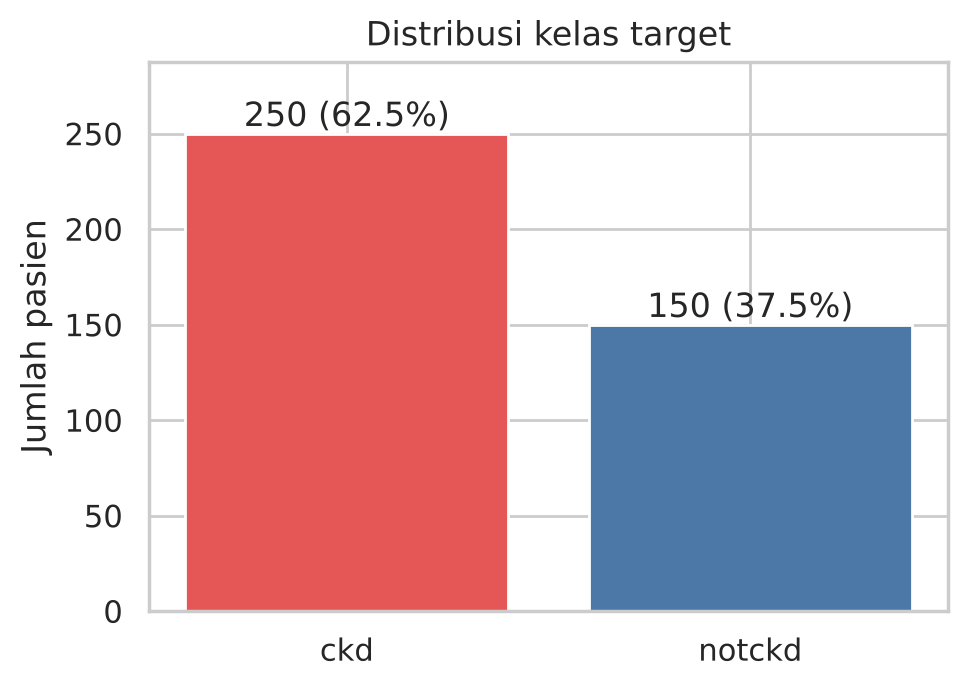

In [5]:
hitung = df["classification"].value_counts()
fig, ax = plt.subplots(figsize=(5, 3.6))
ax.bar(hitung.index, hitung.values, color=[WARNA[1], WARNA[0]])
for i, v in enumerate(hitung.values):
    ax.text(i, v + 4, f"{v} ({v/len(df):.1%})", ha="center")
ax.set_ylabel("Jumlah pasien"); ax.set_title("Distribusi kelas target"); ax.set_ylim(0, hitung.max() * 1.15)
plt.tight_layout(); plt.show()

**Interpretasi.** Kelas `ckd` sebanyak 250 pasien (62,5%) dan `notckd` 150 pasien (37,5%): ada ketidakseimbangan ringan. Artinya akurasi tidak bisa dibaca sendirian (model yang selalu menebak `ckd` sudah benar 62,5%), dan pembagian data wajib memakai `stratify=y`.

### 2.2 Distribusi fitur numerik

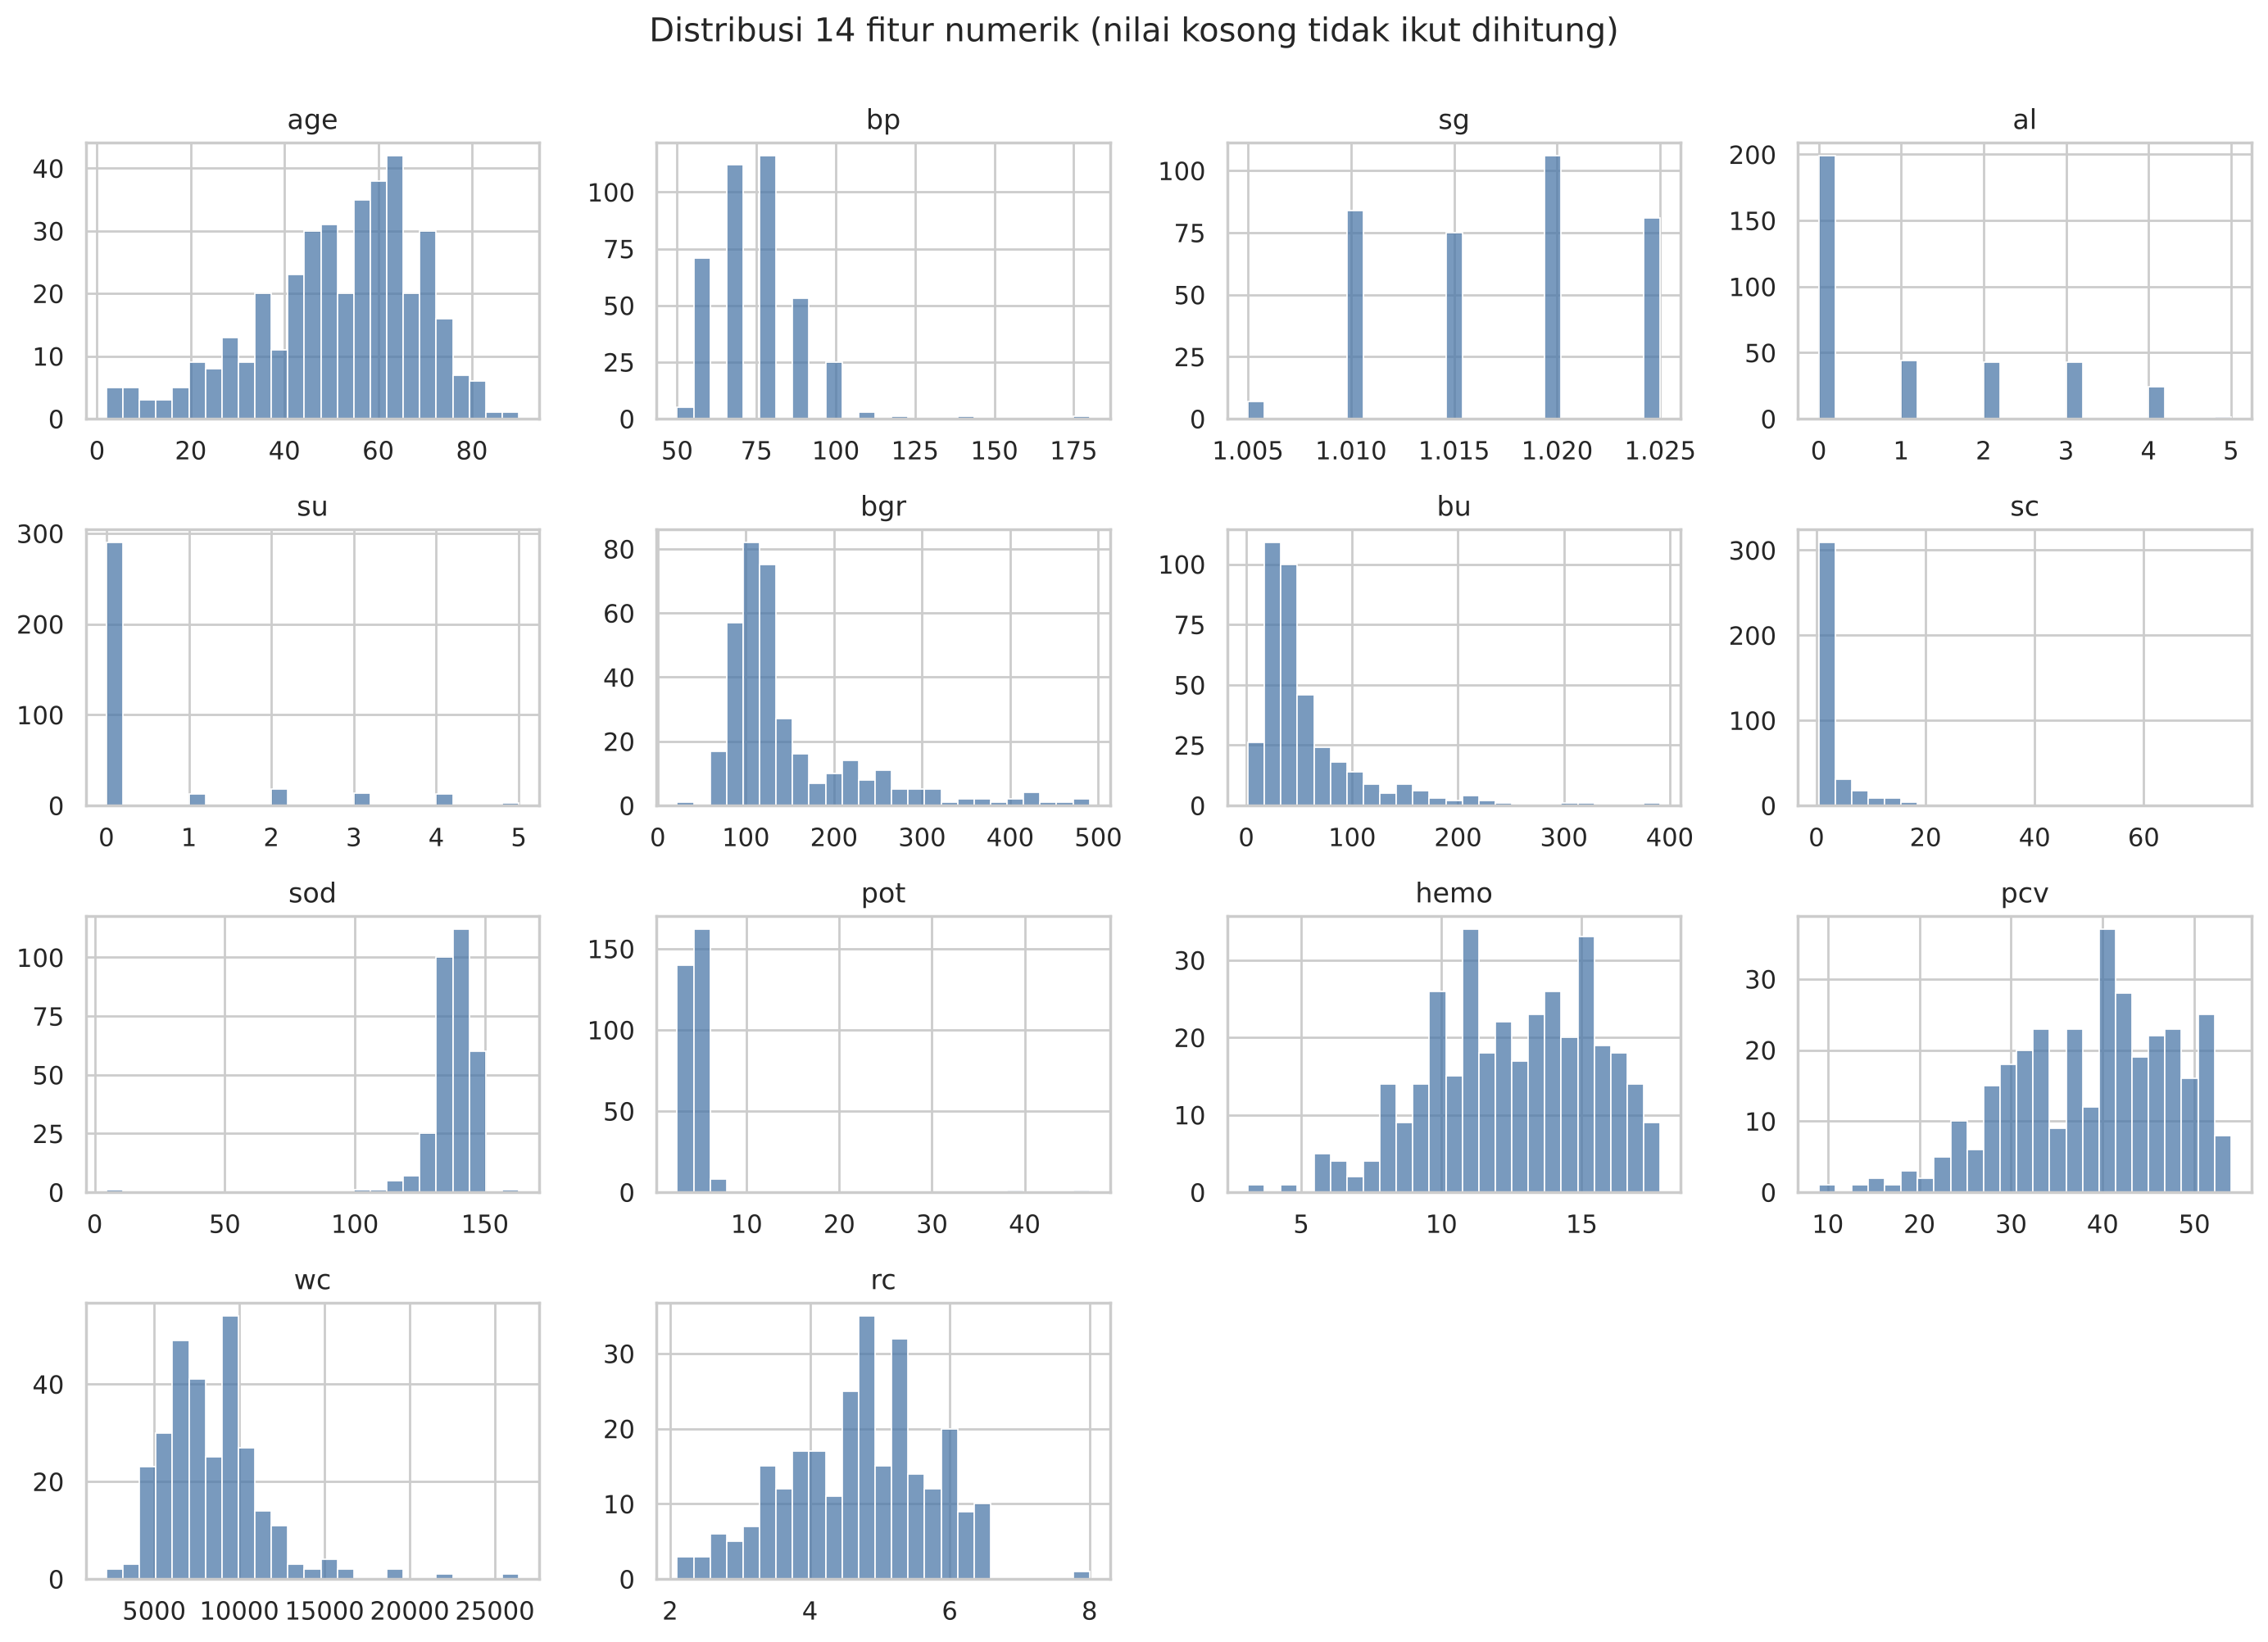

In [6]:
fig, axes = plt.subplots(4, 4, figsize=(14, 10))
for ax, c in zip(axes.ravel(), KOLOM_NUMERIK):
    sns.histplot(df[c].dropna(), bins=25, ax=ax, color="#4C78A8")
    ax.set_title(c); ax.set_xlabel(""); ax.set_ylabel("")
for ax in axes.ravel()[len(KOLOM_NUMERIK):]:
    ax.axis("off")
plt.suptitle("Distribusi 14 fitur numerik (nilai kosong tidak ikut dihitung)", y=1.00)
plt.tight_layout(); plt.show()

**Interpretasi.** Beberapa fitur sangat miring dengan ekor panjang: miring ke kanan pada `sc`, `pot`, `bu`, `bgr`, dan `wc` (ada pasien dengan nilai jauh di atas kebanyakan), serta miring ke kiri pada `sod`. Fitur `sg`, `al`, dan `su` hanya punya beberapa nilai diskret (skala), bukan angka kontinu.

### 2.3 Hubungan fitur numerik dengan target

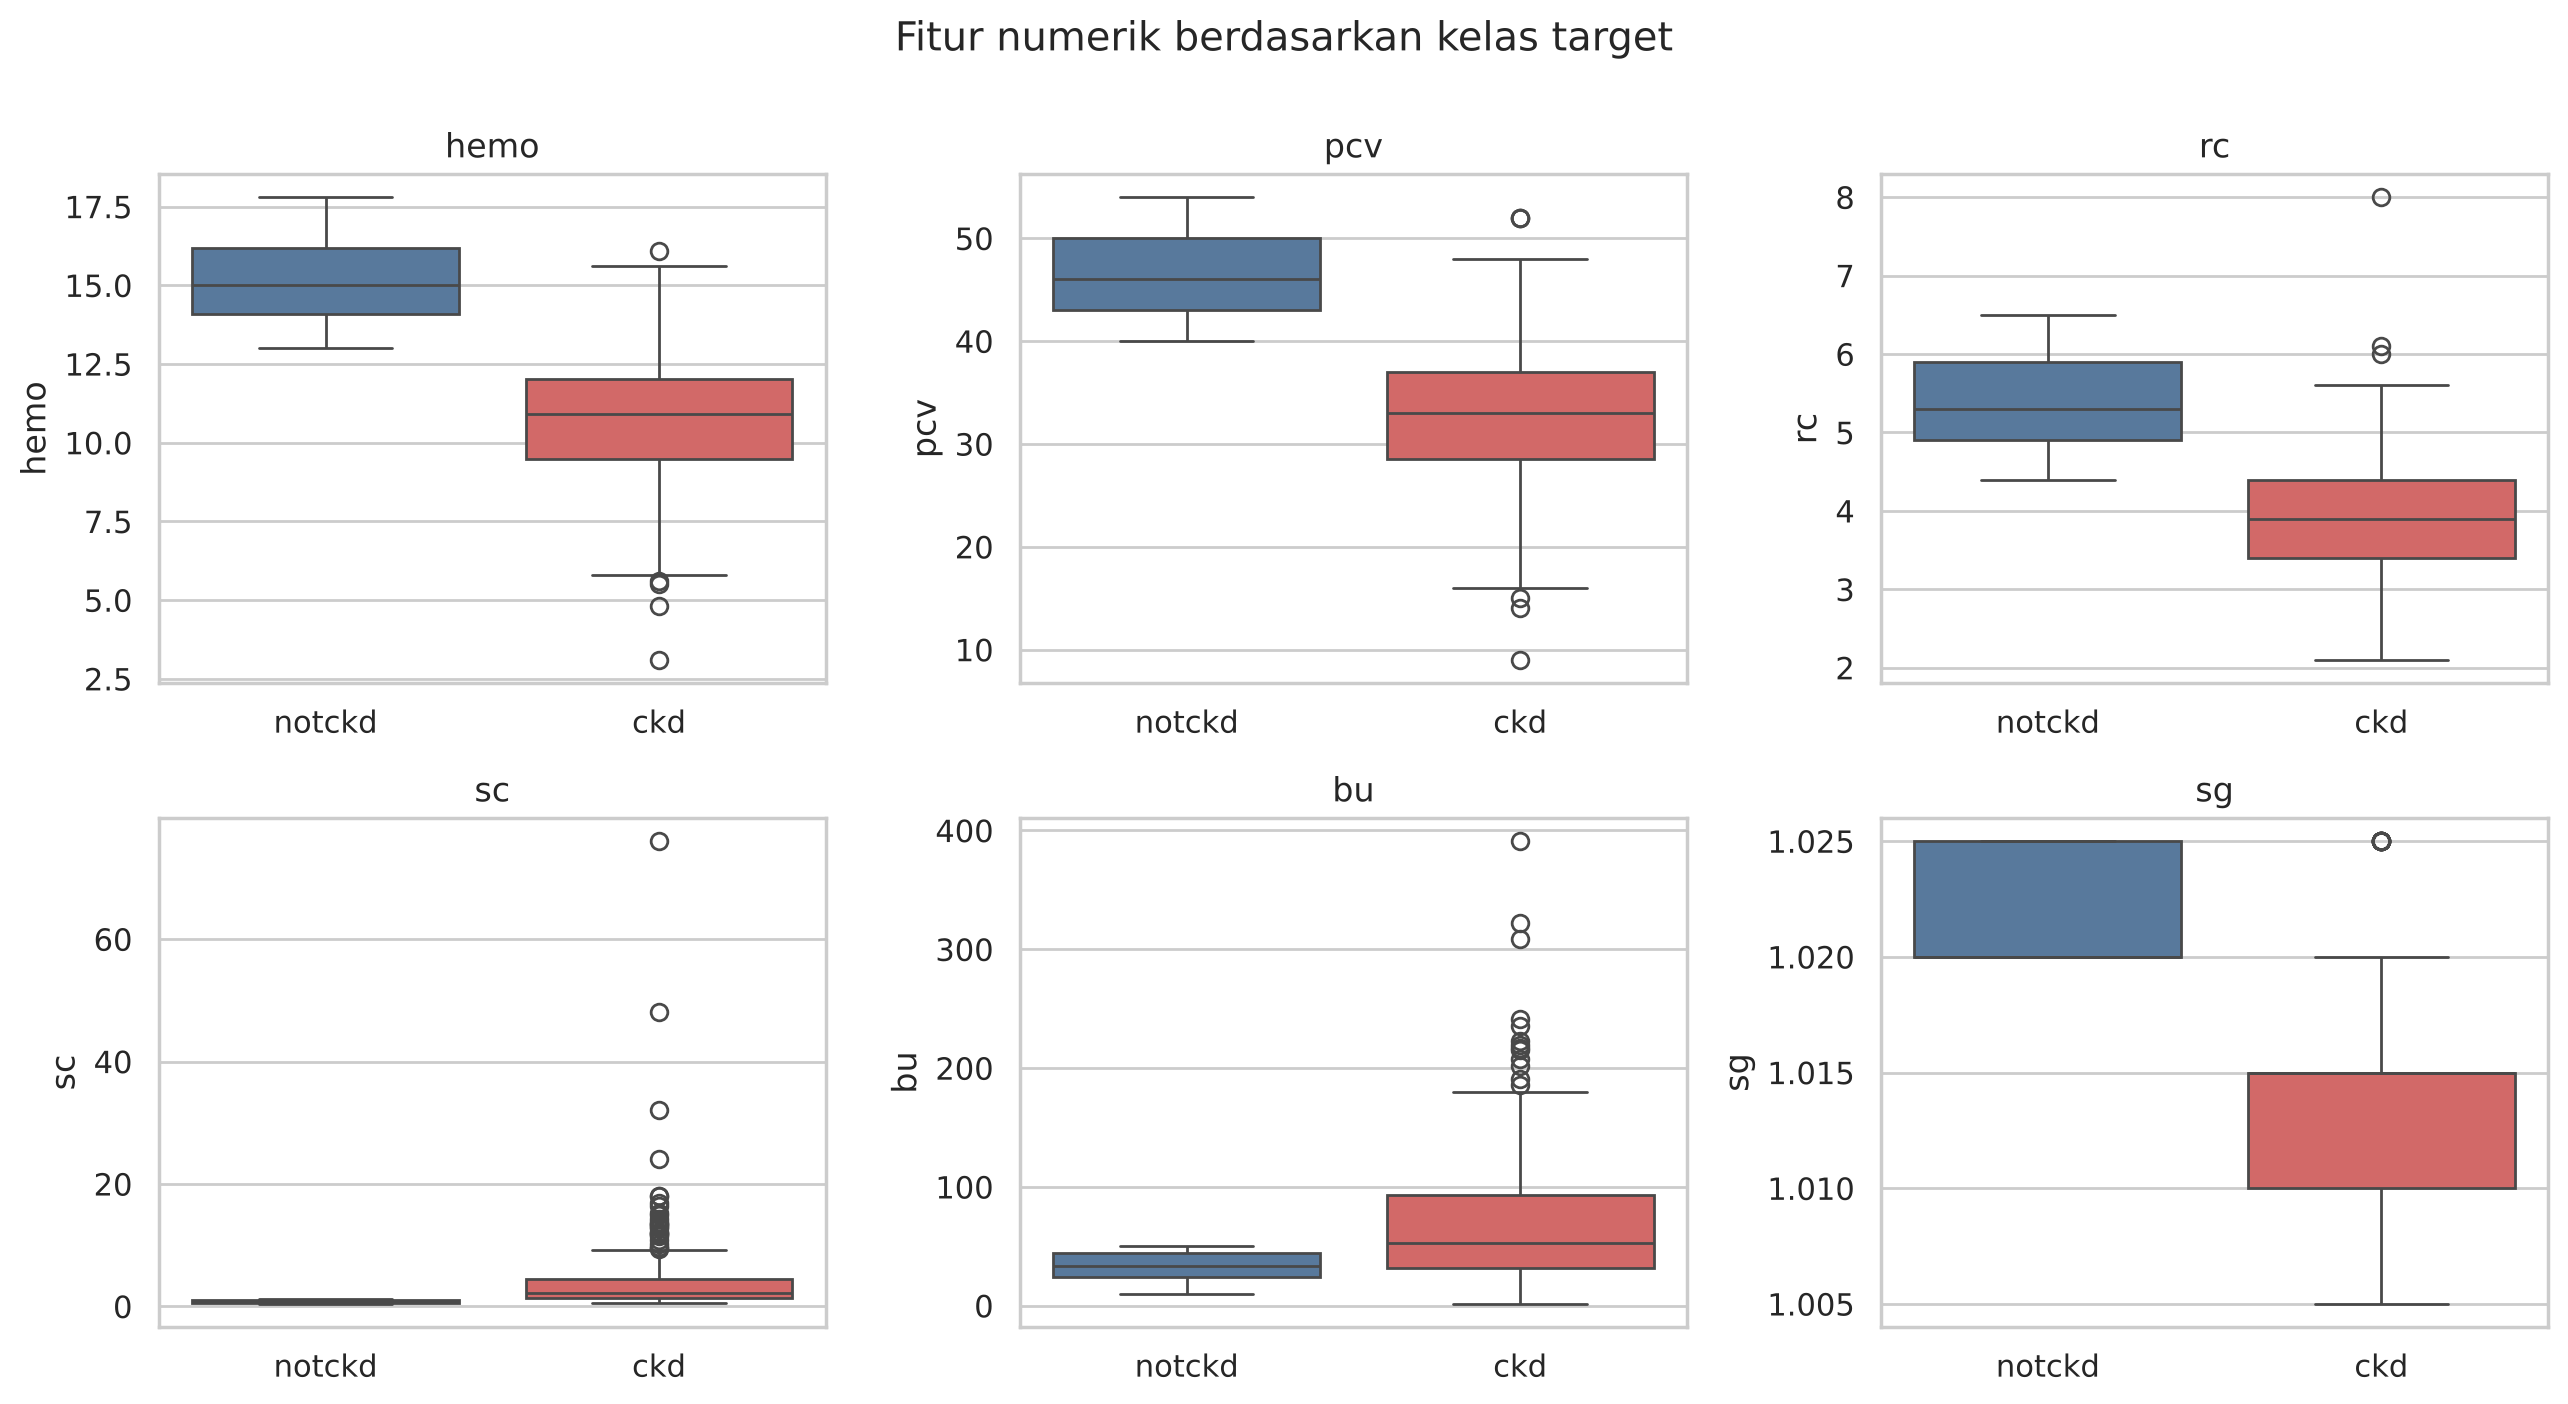

In [7]:
fitur_plot = ["hemo", "pcv", "rc", "sc", "bu", "sg"]
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, c in zip(axes.ravel(), fitur_plot):
    sns.boxplot(data=df, x="classification", y=c, order=["notckd", "ckd"],
                palette=[WARNA[0], WARNA[1]], ax=ax)
    ax.set_xlabel(""); ax.set_title(c)
plt.suptitle("Fitur numerik berdasarkan kelas target", y=1.00)
plt.tight_layout(); plt.show()

**Interpretasi.** Pasien `ckd` punya hemoglobin (`hemo`), hematokrit (`pcv`), sel darah merah (`rc`), dan specific gravity urin (`sg`) yang lebih rendah, serta kreatinin (`sc`) dan urea (`bu`) yang lebih tinggi daripada `notckd`. Misalnya median `hemo` pasien `ckd` sekitar 10,9 dibanding 15,0 pada `notckd`, dan 75% pasien `ckd` punya `hemo` sekitar 12,0 atau kurang, sementara semua `notckd` bernilai 13,0 atau lebih. Kedua kelas hampir tidak tumpang tindih pada fitur-fitur ini, tanda bahwa fitur tersebut sangat informatif dan model diperkirakan bekerja baik.

### 2.4 Hubungan fitur kategorikal dengan target

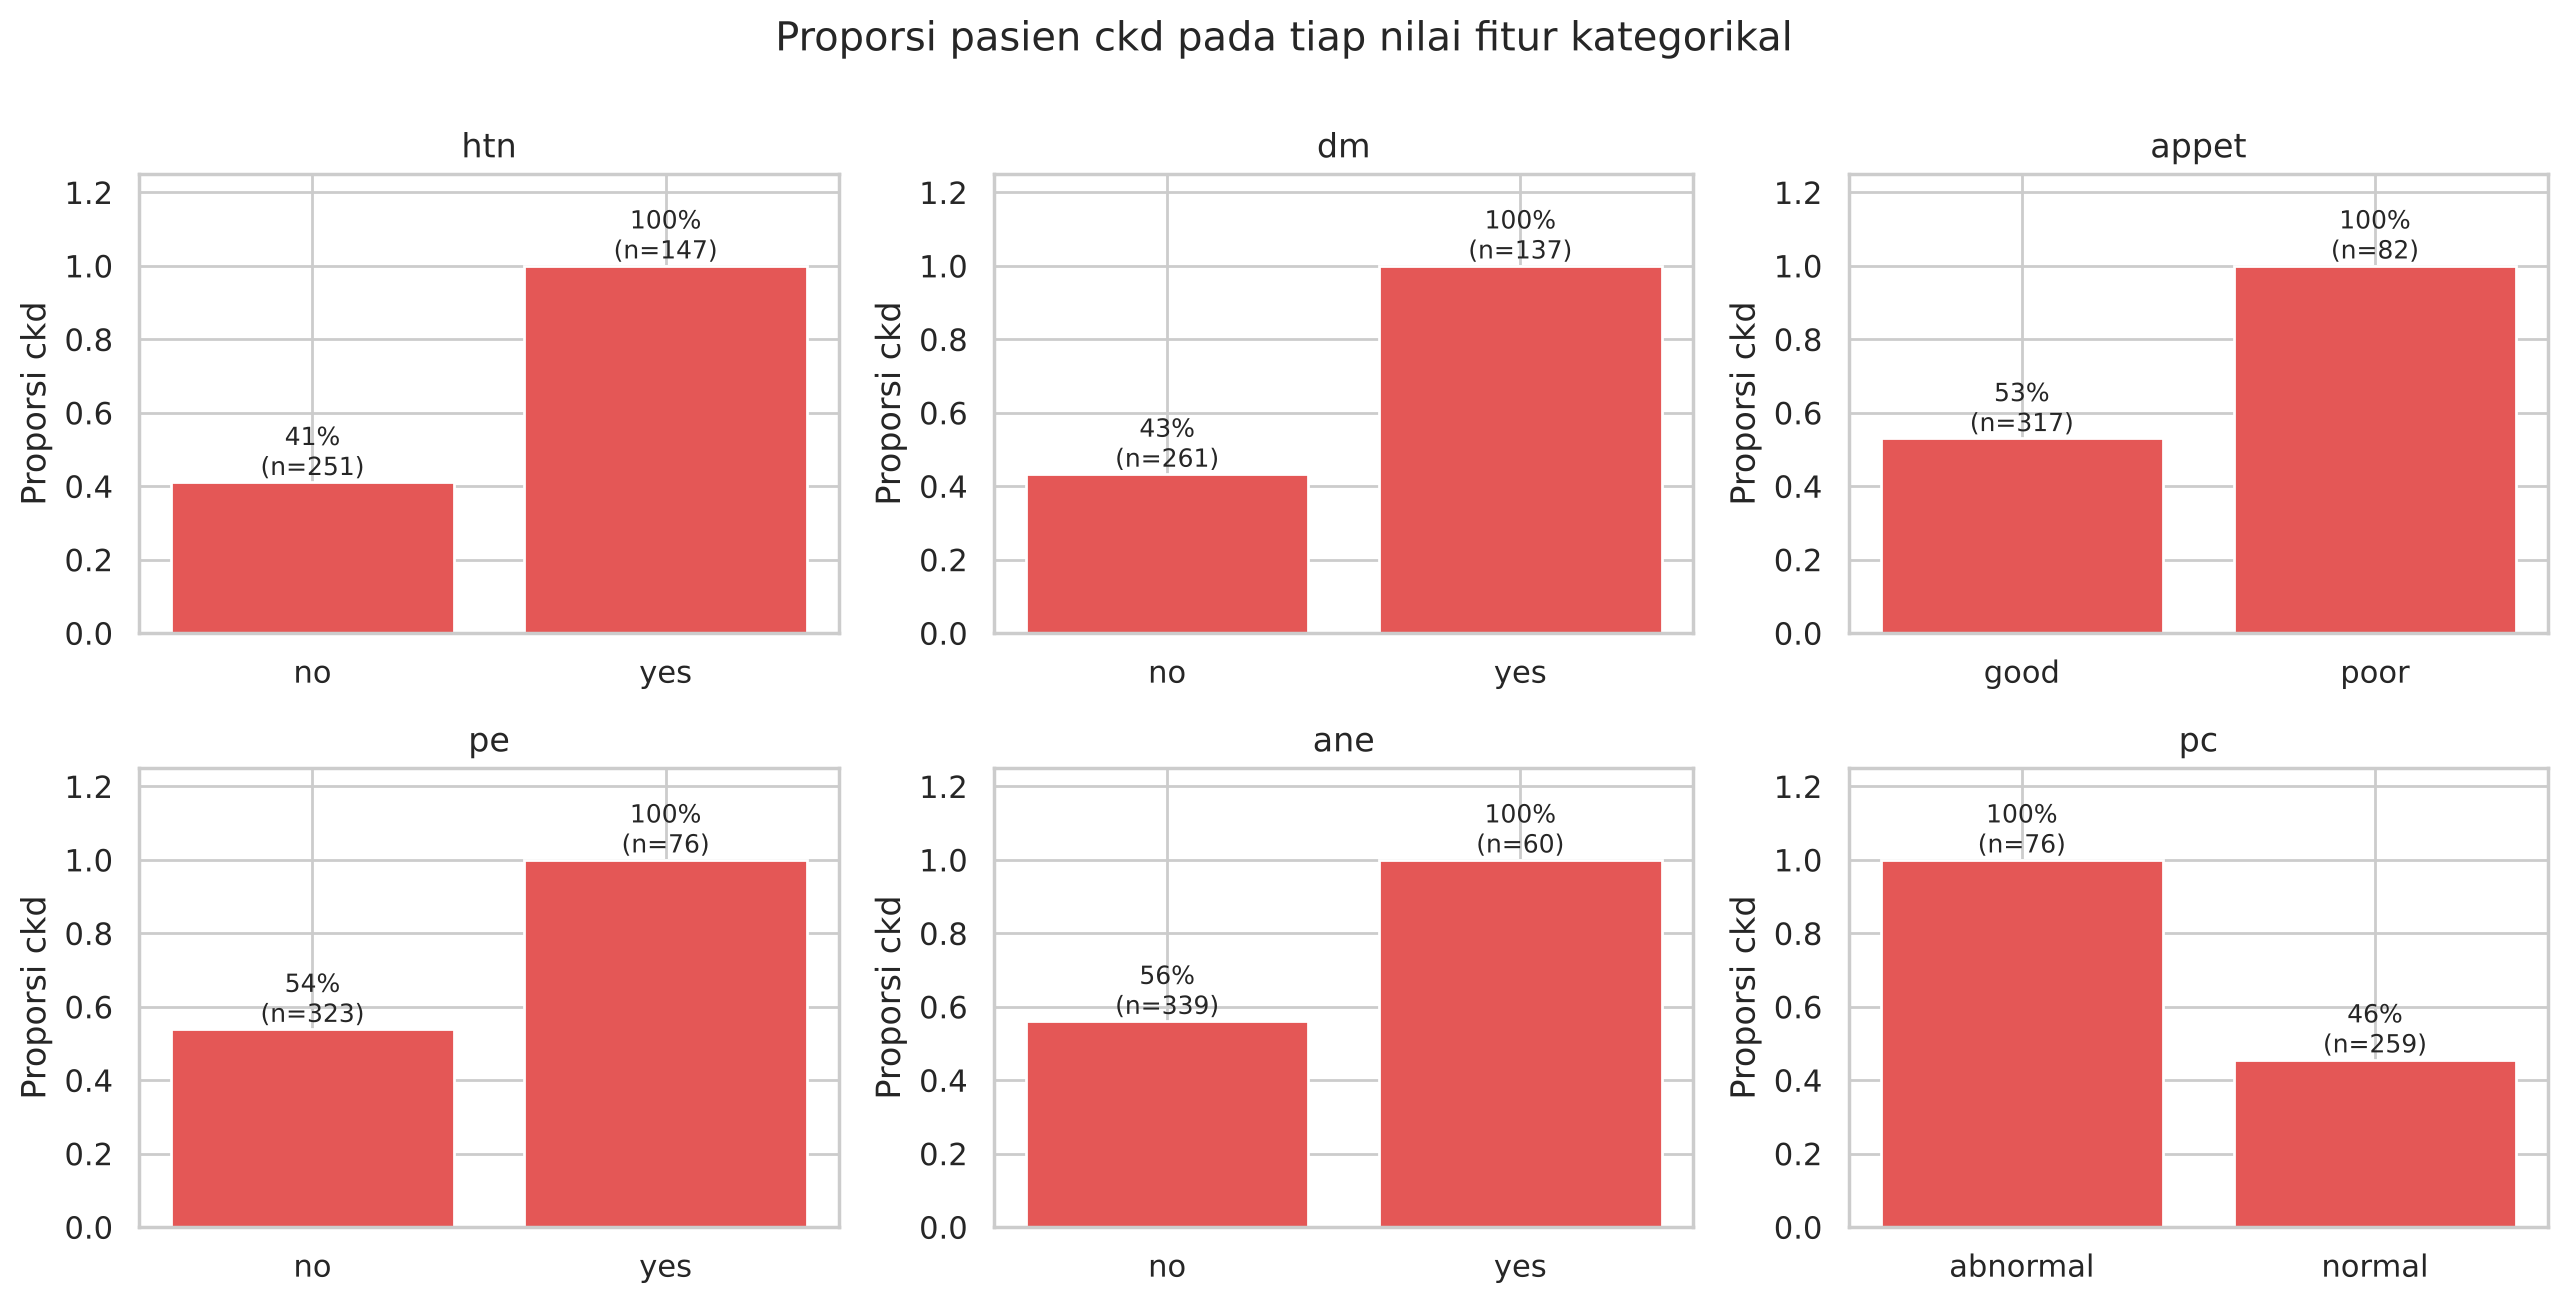

In [8]:
kat_plot = ["htn", "dm", "appet", "pe", "ane", "pc"]
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for ax, c in zip(axes.ravel(), kat_plot):
    tabel = df.groupby(c)["ckd"].agg(["mean", "size"]).reset_index()
    ax.bar(tabel[c], tabel["mean"], color="#E45756")
    for i, (m, n) in enumerate(zip(tabel["mean"], tabel["size"])):
        ax.text(i, m + 0.02, f"{m:.0%}\n(n={n})", ha="center", fontsize=9)
    ax.set_ylim(0, 1.25); ax.set_title(c); ax.set_ylabel("Proporsi ckd"); ax.set_xlabel("")
plt.suptitle("Proporsi pasien ckd pada tiap nilai fitur kategorikal", y=1.00)
plt.tight_layout(); plt.show()

**Interpretasi.** Semua pasien dengan hipertensi (`htn = yes`), diabetes (`dm = yes`), nafsu makan buruk (`appet = poor`), edema (`pe = yes`), anemia (`ane = yes`), atau pus cell abnormal (`pc = abnormal`) berasal dari kelas `ckd` (100%). Kebalikannya tidak berlaku: pada `htn = no` masih ada sekitar 41% pasien `ckd`, jadi fitur ini bagus sebagai petunjuk tetapi tidak cukup sebagai satu-satunya aturan.

### Keputusan saya (Tahap 2)

Dari grafik saya menyimpulkan tiga hal. **Pertama**, kelas tidak seimbang (62,5% vs 37,5%), jadi saya memakai `stratify=y` dan `StratifiedKFold`, dan menilai model dengan presisi, recall, dan F1, bukan akurasi saja. **Kedua**, ada nilai ekstrem pada `bgr`, `bu`, `sc`, `wc`; nilai-nilai ini kemungkinan kondisi klinis nyata pada pasien sakit sehingga perlu diputuskan dengan hati-hati di pra-pemrosesan. **Ketiga**, fitur seperti `hemo`, `pcv`, `rc`, `sc`, `sg` memisahkan kedua kelas dengan jelas, sehingga saya menduga hasil model akan tinggi dan perlu saya cek apakah ada kebocoran data atau sekadar data yang mudah dipisahkan.

# 3. Pra-pemrosesan Data

### 3.1 Kategori yang ditulis tidak konsisten (bukti sebelum dan sesudah)

In [9]:
for c in ["classification", "dm", "cad"]:
    sebelum = df_raw[c].map(repr).value_counts(dropna=False).to_dict()
    sesudah = df[c].value_counts(dropna=False).to_dict()
    print(f"{c:15s} SEBELUM: {sebelum}")
    print(f"{'':15s} SESUDAH: {sesudah}\n")

for c in ["pcv", "wc", "rc"]:
    aneh = df_raw[c].dropna()[pd.to_numeric(df_raw[c].dropna(), errors="coerce").isna()].map(repr).unique()
    print(f"{c}: nilai non-angka di file asli = {list(aneh)} -> diubah menjadi NaN")

classification  SEBELUM: {"'ckd'": 248, "'notckd'": 150, "'ckd\\t'": 2}
                SESUDAH: {'ckd': 250, 'notckd': 150}

dm              SEBELUM: {"'no'": 258, "'yes'": 134, "'\\tno'": 3, "'\\tyes'": 2, 'nan': 2, "' yes'": 1}
                SESUDAH: {'no': 261, 'yes': 137, nan: 2}

cad             SEBELUM: {"'no'": 362, "'yes'": 34, "'\\tno'": 2, 'nan': 2}
                SESUDAH: {'no': 364, 'yes': 34, nan: 2}

pcv: nilai non-angka di file asli = ["'\\t?'"] -> diubah menjadi NaN
wc: nilai non-angka di file asli = ["'\\t?'"] -> diubah menjadi NaN
rc: nilai non-angka di file asli = ["'\\t?'"] -> diubah menjadi NaN


### 3.2 Duplikat

In [10]:
print("Baris duplikat (setelah kolom id dibuang):", df.drop(columns="ckd").duplicated().sum())
print("Nilai id unik di file asli:", df_raw["id"].is_unique)

Baris duplikat (setelah kolom id dibuang): 0
Nilai id unik di file asli: True


### 3.3 Missing value

,rbc,rc,wc,pot,sod,pcv,pc,hemo,su,sg,al,bgr,bu,sc,bp,age,pcc,ba,htn,dm,cad,appet,pe,ane
jumlah_kosong,152.0,131.0,106.0,88.0,87.0,71.0,65.0,52.0,49.0,47.0,46.0,44.0,19.0,17.0,12.0,9.0,4.0,4.0,2.0,2.0,2.0,1.0,1.0,1.0
persen,38.0,32.8,26.5,22.0,21.8,17.8,16.2,13.0,12.2,11.8,11.5,11.0,4.8,4.2,3.0,2.2,1.0,1.0,0.5,0.5,0.5,0.2,0.2,0.2


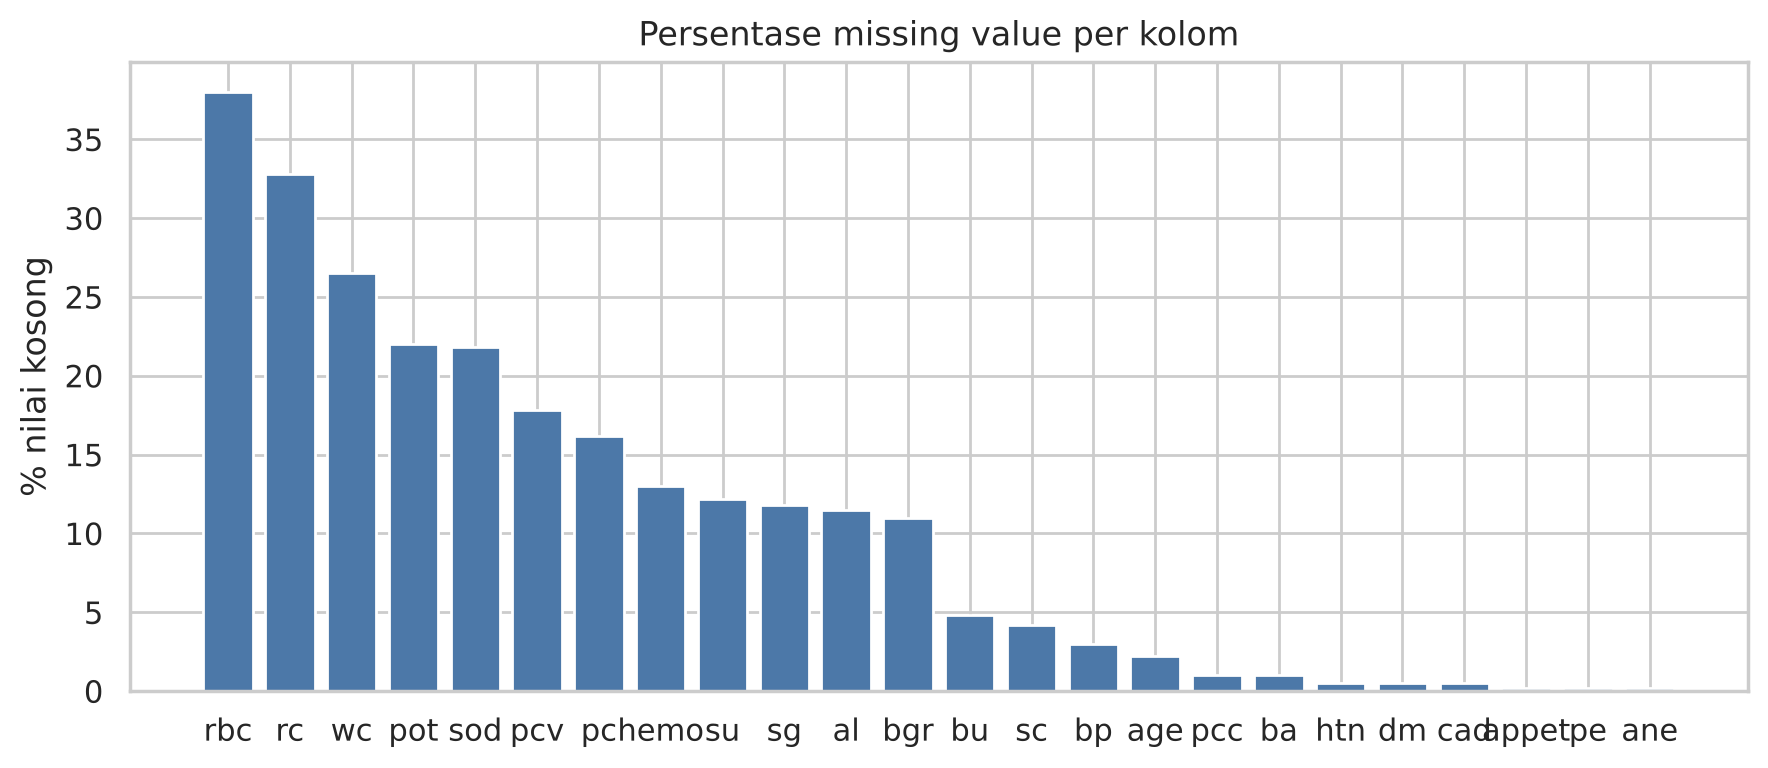


Persen kosong menurut kelas (6 kolom paling banyak kosong):


,rbc,rc,wc,pot,sod,pcv
classification,,,,,,
ckd,57.2,49.6,39.6,33.2,32.8,26.8
notckd,6.0,4.7,4.7,3.3,3.3,2.7


In [11]:
mv = pd.DataFrame({
    "jumlah_kosong": df.drop(columns=["classification", "ckd"]).isna().sum(),
})
mv["persen"] = (mv["jumlah_kosong"] / len(df) * 100).round(1)
mv = mv[mv["jumlah_kosong"] > 0].sort_values("persen", ascending=False)
display(mv.T)

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(mv.index, mv["persen"], color="#4C78A8")
ax.set_ylabel("% nilai kosong"); ax.set_title("Persentase missing value per kolom")
plt.tight_layout(); plt.show()

# Apakah kekosongan berkaitan dengan kelas? (hanya deskriptif, tidak dipakai untuk melatih apa pun)
kolom_banyak_kosong = mv.index[:6]
print("\nPersen kosong menurut kelas (6 kolom paling banyak kosong):")
df.groupby("classification")[list(kolom_banyak_kosong)].apply(lambda g: (g.isna().mean() * 100).round(1))

**Interpretasi.** Kolom `rbc` (sekitar 38%), `rc` (sekitar 33%), `wc` (sekitar 26%), `pot` dan `sod` (sekitar 22%) paling banyak kosong. Tabel terakhir menunjukkan hal penting: pada kelas `notckd` hanya sekitar 3-6% nilai yang kosong, sedangkan pada kelas `ckd` mencapai 27-57%. Jadi pola kekosongan berkaitan dengan kelas, kemungkinan akibat cara data dikumpulkan di rumah sakit.

### 3.4 Outlier (metode IQR)

In [12]:
def hitung_outlier(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    batas_bawah, batas_atas = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n = ((s < batas_bawah) | (s > batas_atas)).sum()
    return pd.Series({"Q1": q1, "Q3": q3, "batas_bawah": batas_bawah, "batas_atas": batas_atas,
                      "jumlah_outlier": n, "persen_dari_terisi": n / s.notna().sum() * 100})

tabel_outlier = df[KOLOM_NUMERIK].apply(hitung_outlier).T.round(2)
tabel_outlier.sort_values("jumlah_outlier", ascending=False)

,Q1,Q3,batas_bawah,batas_atas,jumlah_outlier,persen_dari_terisi
su,0.00,0.00,0.00,0.00,61.0,17.38
sc,0.90,2.80,-1.95,5.65,51.0,13.32
bu,27.00,66.00,-31.50,124.50,38.0,9.97
bp,70.00,80.00,55.00,95.00,36.0,9.28
bgr,99.00,163.00,3.00,259.00,34.0,9.55
sod,135.00,142.00,124.50,152.50,16.0,5.11
age,42.00,64.50,8.25,98.25,10.0,2.56
wc,6500.00,9800.00,1550.00,14750.00,10.0,3.40
pot,3.80,4.90,2.15,6.55,4.0,1.28
hemo,10.30,15.00,3.25,22.05,1.0,0.29


In [13]:
# Apakah outlier berasal dari kelas ckd? (deskriptif)
ringkas = []
for c in ["bgr", "bu", "sc", "wc", "pot", "sod"]:
    s = df[c]; q1, q3 = s.quantile(.25), s.quantile(.75); iqr = q3 - q1
    mask = (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)
    ringkas.append({"fitur": c, "outlier": int(mask.sum()), "dari_ckd": int(df.loc[mask, "ckd"].sum())})
pd.DataFrame(ringkas)

,fitur,outlier,dari_ckd
0,bgr,34,34
1,bu,38,38
2,sc,51,51
3,wc,10,10
4,pot,4,4
5,sod,16,16


**Interpretasi.** Jumlah outlier terbanyak ada pada `su` (61), `sc` (51), `bu` (38), `bp` (36), dan `bgr` (34). Angka `su` perlu dibaca hati-hati: Q1 dan Q3-nya sama-sama 0 sehingga IQR = 0 dan setiap nilai di atas 0 otomatis disebut outlier, padahal itu hanya skala diskret. Tabel kedua menunjukkan **seluruh** outlier pada `bgr`, `bu`, `sc`, `wc`, `pot`, dan `sod` berasal dari pasien `ckd` (misalnya 51 dari 51 untuk `sc`), begitu juga outlier `bp` (36 dari 36) dan semua nilai `su` di atas 0. Jadi nilai ekstrem itu mencerminkan kondisi klinis (misalnya kreatinin dan urea sangat tinggi saat ginjal gagal menyaring), bukan salah catat.

### 3.5 Pembagian data latih-uji (dilakukan SEBELUM imputasi, encoding, dan scaling)

In [14]:
FITUR = KOLOM_NUMERIK + KOLOM_KATEGORIK
X = df[FITUR]
y = df["ckd"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("Proporsi ckd -> semua: %.3f | latih: %.3f | uji: %.3f" % (y.mean(), y_train.mean(), y_test.mean()))

X_train: (320, 24) | X_test: (80, 24)
Proporsi ckd -> semua: 0.625 | latih: 0.625 | uji: 0.625


### 3.6 Imputasi, encoding, dan scaling lewat `ColumnTransformer` + `Pipeline`

In [15]:
pra_numerik = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler()),
])
pra_kategorik = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(drop="if_binary", handle_unknown="ignore")),
])
praproses = ColumnTransformer([
    ("num", pra_numerik, KOLOM_NUMERIK),
    ("kat", pra_kategorik, KOLOM_KATEGORIK),
])

# Demonstrasi: transformer di-fit HANYA pada data latih, lalu dipakai untuk mengubah data uji.
praproses.fit(X_train)
Xt_train = praproses.transform(X_train)
Xt_test = praproses.transform(X_test)
print("Bentuk setelah transformasi -> latih:", Xt_train.shape, "| uji:", Xt_test.shape)
print("Nilai kosong tersisa:", np.isnan(Xt_train).sum(), "(latih),", np.isnan(Xt_test).sum(), "(uji)")

median_latih = pd.Series(praproses.named_transformers_["num"]["imputer"].statistics_, index=KOLOM_NUMERIK)
print("\nMedian yang dipelajari dari DATA LATIH (dipakai mengisi kosong di data latih maupun uji):")
print(median_latih.round(2).to_dict())

Bentuk setelah transformasi -> latih: (320, 24) | uji: (80, 24)
Nilai kosong tersisa: 0 (latih), 0 (uji)

Median yang dipelajari dari DATA LATIH (dipakai mengisi kosong di data latih maupun uji):
{'age': 55.0, 'bp': 70.0, 'sg': 1.02, 'al': 0.0, 'su': 0.0, 'bgr': 118.0, 'bu': 42.0, 'sc': 1.3, 'sod': 138.0, 'pot': 4.35, 'hemo': 12.6, 'pcv': 40.0, 'wc': 7850.0, 'rc': 4.8}


### Keputusan saya (Tahap 3)

- **Kategori tidak konsisten:** nilai seperti `' yes'`, `'\tno'`, dan `'ckd\t'` berisi spasi/tab yang membuat satu kategori terhitung beberapa kali. Saya merapikannya dengan `strip()` sehingga tersisa dua nilai bersih per kolom, dan target tinggal `ckd` / `notckd`. Tanda `'\t?'` pada `pcv`, `wc`, `rc` saya ubah menjadi nilai kosong lalu kolomnya dikonversi ke angka.
- **Duplikat:** tidak ada baris duplikat, jadi tidak ada yang dibuang.
- **Missing value:** saya **tidak membuang baris** karena hampir setengah baris punya setidaknya satu nilai kosong dan data hanya 400. Saya juga tidak membuang kolom, termasuk `rbc` yang paling banyak kosong. Fitur numerik diisi **median** (tahan terhadap nilai ekstrem), fitur kategorikal diisi **modus**. Imputer dilatih hanya pada data latih di dalam `Pipeline`, sehingga tidak ada kebocoran data uji.
- **Outlier:** saya **mempertahankan** outlier. Alasannya, nilai ekstrem itu berasal dari pasien `ckd` dan merupakan sinyal klinis, jadi menghapusnya justru membuang kasus sakit yang ingin dikenali. Untuk `su` (IQR = 0), "outlier" hanya artefak skala diskret sehingga memang tidak boleh dihapus. Sebagai gantinya saya memakai **RobustScaler** (berbasis median dan IQR) agar outlier tidak mendominasi jarak pada KNN.
- **Encoding:** semua fitur kategorikal bernilai dua kategori, jadi dipakai `OneHotEncoder(drop="if_binary")` (menjadi satu kolom 0/1 per fitur). `handle_unknown="ignore"` mencegah error bila ada kategori baru. Fitur `sg`, `al`, `su` tetap dianggap numerik karena skalanya berurutan.
- **Scaling:** KNN dan SVM berbasis jarak, jadi fitur dengan satuan besar (misalnya `wc` dalam ribuan) akan mendominasi tanpa scaling.
- **Anti-kebocoran:** data dibagi 80:20 dengan `stratify=y` dan `random_state=SEED` **sebelum** imputasi, encoding, dan scaling; semuanya dilakukan di dalam `Pipeline`/`ColumnTransformer` yang di-fit pada data latih saja (termasuk di dalam setiap lipatan cross-validation).
- **Catatan penting:** kekosongan data ternyata jauh lebih sering pada kelas `ckd` daripada `notckd`. Saya sengaja **tidak** menambahkan fitur "penanda kosong" (`add_indicator`) karena itu akan membuat model belajar dari kebiasaan pengumpulan data, bukan dari kondisi medis pasien. Hal ini saya cantumkan sebagai keterbatasan.

# 4. Pemodelan

Semua model dibungkus dalam `Pipeline(praproses -> model)`. Cross-validation 5-fold memakai `StratifiedKFold(shuffle=True, random_state=SEED)` **hanya pada data latih**. Data uji belum disentuh sampai Tahap 5.

In [16]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
METRIK = ["accuracy", "precision", "recall", "f1"]

def buat_model(estimator):
    return Pipeline([("praproses", praproses), ("model", estimator)])

def skor_cv(estimator):
    hasil = cross_validate(buat_model(estimator), X_train, y_train, cv=cv, scoring=METRIK)
    out = {m: hasil["test_" + m].mean() for m in METRIK}
    out["std_accuracy"] = hasil["test_accuracy"].std()
    return out

### 4.1 Baseline: DummyClassifier

In [17]:
skor_dummy = skor_cv(DummyClassifier(strategy="most_frequent", random_state=SEED))
pd.DataFrame([skor_dummy], index=["DummyClassifier (most_frequent)"]).round(4)

,accuracy,precision,recall,f1,std_accuracy
DummyClassifier (most_frequent),0.625,0.625,1.0,0.7692,0.0


**Interpretasi.** Baseline selalu menebak kelas mayoritas (`ckd`) sehingga akurasinya sama dengan proporsi `ckd` pada data latih (62,5%). Recall-nya 1,0 hanya karena ia menebak `ckd` untuk semua orang; presisinya 62,5% menunjukkan bahwa itu bukan kemampuan membedakan. Model harus mengalahkan akurasi dan presisi ini.

### 4.2 KNN: memilih nilai k dengan 5-fold CV

,accuracy,precision,recall,f1,std_accuracy
k,,,,,
1,0.9688,0.9947,0.955,0.9744,0.0171
2,0.9438,1.0000,0.910,0.9528,0.0125
3,0.9625,0.9947,0.945,0.9690,0.0212
4,0.9594,1.0000,0.935,0.9661,0.0212
5,0.9594,1.0000,0.935,0.9661,0.0212
6,0.9500,1.0000,0.920,0.9579,0.0250
7,0.9562,1.0000,0.930,0.9634,0.0207
8,0.9531,1.0000,0.925,0.9607,0.0221
9,0.9594,1.0000,0.935,0.9661,0.0212


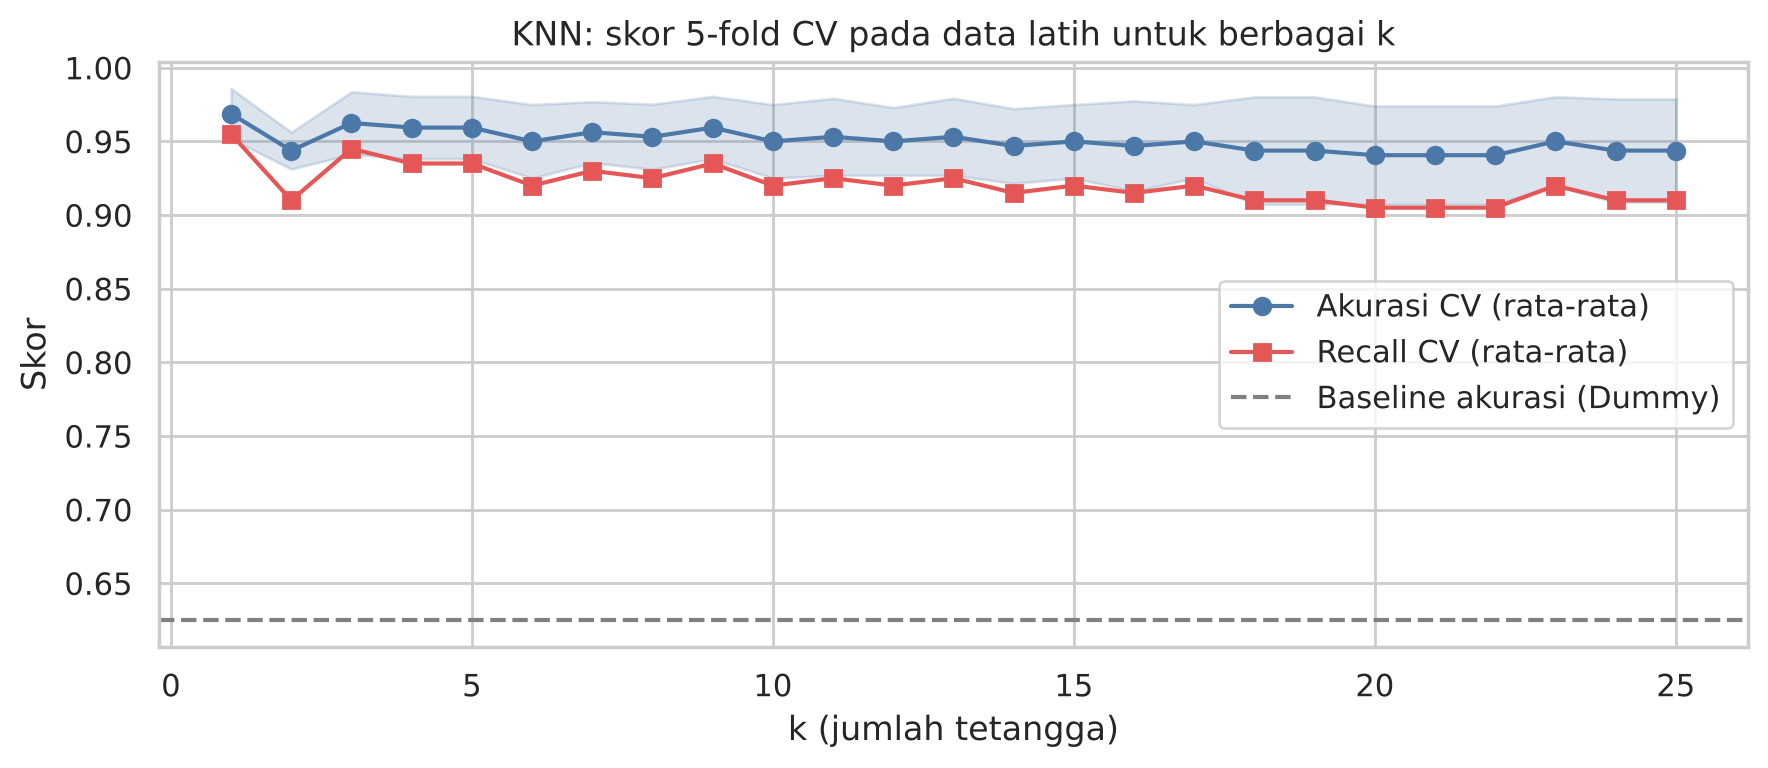

In [18]:
daftar_k = list(range(1, 26))
baris = []
for k in daftar_k:
    s = skor_cv(KNeighborsClassifier(n_neighbors=k))
    baris.append({"k": k, **s})
tabel_knn = pd.DataFrame(baris).set_index("k")
display(tabel_knn.round(4).head(10))

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(tabel_knn.index, tabel_knn["accuracy"], marker="o", label="Akurasi CV (rata-rata)", color="#4C78A8")
ax.fill_between(tabel_knn.index, tabel_knn["accuracy"] - tabel_knn["std_accuracy"],
                tabel_knn["accuracy"] + tabel_knn["std_accuracy"], alpha=0.2, color="#4C78A8")
ax.plot(tabel_knn.index, tabel_knn["recall"], marker="s", label="Recall CV (rata-rata)", color="#E45756")
ax.axhline(skor_dummy["accuracy"], ls="--", color="gray", label="Baseline akurasi (Dummy)")
ax.set_xlabel("k (jumlah tetangga)"); ax.set_ylabel("Skor"); ax.set_title("KNN: skor 5-fold CV pada data latih untuk berbagai k")
ax.legend(); plt.tight_layout(); plt.show()

In [19]:
# Aturan pemilihan k: aturan 1 standard error.
# Ambil skor akurasi CV tertinggi, lalu pilih k TERBESAR (model paling halus/stabil)
# yang akurasinya masih dalam 1 standard error dari skor tertinggi tersebut.
terbaik = tabel_knn["accuracy"].idxmax()
se = tabel_knn.loc[terbaik, "std_accuracy"] / np.sqrt(cv.get_n_splits())
ambang = tabel_knn.loc[terbaik, "accuracy"] - se
kandidat = tabel_knn[tabel_knn["accuracy"] >= ambang]
k_terpilih = int(kandidat.index.max())

print(f"k dengan akurasi CV tertinggi : {terbaik} (akurasi = {tabel_knn.loc[terbaik, 'accuracy']:.4f})")
print(f"Ambang 1 SE                   : {ambang:.4f}")
print(f"k yang memenuhi ambang        : {list(kandidat.index)}")
print(f"k TERPILIH                    : {k_terpilih}")
tabel_knn.loc[[terbaik, k_terpilih]].round(4)

k dengan akurasi CV tertinggi : 1 (akurasi = 0.9688)
Ambang 1 SE                   : 0.9611
k yang memenuhi ambang        : [1, 3]
k TERPILIH                    : 3


,accuracy,precision,recall,f1,std_accuracy
k,,,,,
1,0.9688,0.9947,0.955,0.9744,0.0171
3,0.9625,0.9947,0.945,0.9690,0.0212


### 4.3 SVM sebagai algoritma kedua (nilai tambah): memilih kernel dan C

,kernel,C,accuracy,precision,recall,f1,std_accuracy
0,linear,0.1,0.9906,1.0000,0.985,0.9922,0.0188
1,linear,1.0,0.9844,0.9951,0.980,0.9872,0.0171
2,linear,10.0,0.9844,1.0000,0.975,0.9871,0.0198
3,linear,100.0,0.9844,1.0000,0.975,0.9871,0.0198
4,rbf,0.1,0.9781,1.0000,0.965,0.9819,0.0212
5,rbf,1.0,0.9875,1.0000,0.980,0.9898,0.0117
6,rbf,10.0,0.9906,1.0000,0.985,0.9923,0.0125
7,rbf,100.0,0.9875,1.0000,0.980,0.9897,0.0182


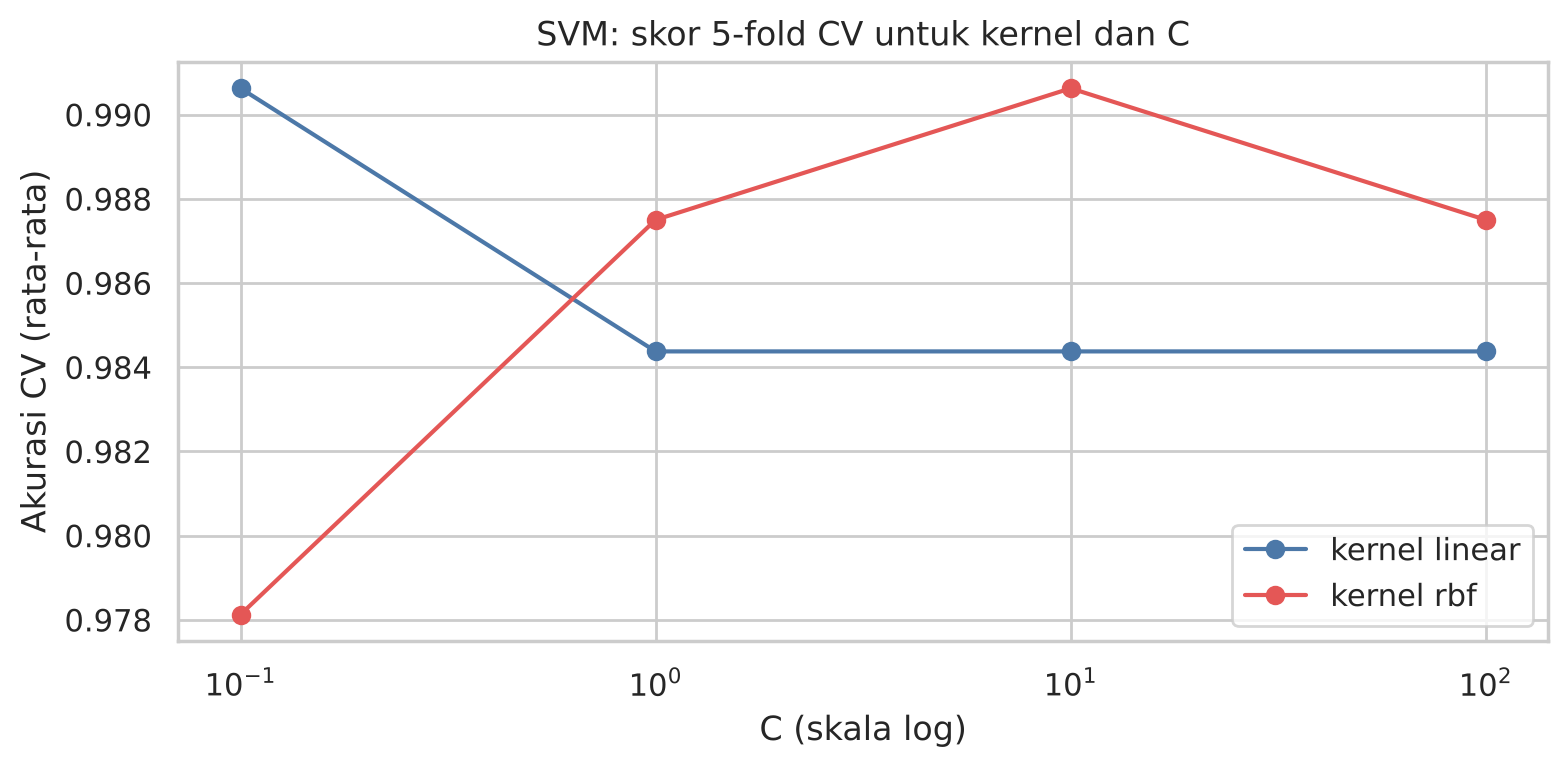

SVM terpilih: kernel = rbf, C = 10.0


In [20]:
baris = []
for kernel in ["linear", "rbf"]:
    for C in [0.1, 1, 10, 100]:
        s = skor_cv(SVC(kernel=kernel, C=C, random_state=SEED))
        baris.append({"kernel": kernel, "C": C, **s})
tabel_svm = pd.DataFrame(baris)
display(tabel_svm.round(4))

fig, ax = plt.subplots(figsize=(8, 4))
for kernel, warna in [("linear", "#4C78A8"), ("rbf", "#E45756")]:
    t = tabel_svm[tabel_svm["kernel"] == kernel]
    ax.plot(t["C"], t["accuracy"], marker="o", label=f"kernel {kernel}", color=warna)
ax.set_xscale("log"); ax.set_xlabel("C (skala log)"); ax.set_ylabel("Akurasi CV (rata-rata)")
ax.set_title("SVM: skor 5-fold CV untuk kernel dan C"); ax.legend()
plt.tight_layout(); plt.show()

# Aturan: akurasi CV tertinggi; bila sama, ambil F1 tertinggi.
urut = tabel_svm.sort_values(["accuracy", "f1"], ascending=False).iloc[0]
kernel_terpilih, C_terpilih = urut["kernel"], float(urut["C"])
print(f"SVM terpilih: kernel = {kernel_terpilih}, C = {C_terpilih}")

### 4.4 Ringkasan skor CV tiga model (data latih)

In [21]:
ringkasan_cv = pd.DataFrame({
    "DummyClassifier": skor_dummy,
    f"KNN (k={k_terpilih})": tabel_knn.loc[k_terpilih].to_dict(),
    f"SVM ({kernel_terpilih}, C={C_terpilih:g})": urut[METRIK + ["std_accuracy"]].to_dict(),
}).T[METRIK + ["std_accuracy"]].astype(float)
ringkasan_cv.round(4)

,accuracy,precision,recall,f1,std_accuracy
DummyClassifier,0.6250,0.6250,1.000,0.7692,0.0000
KNN (k=3),0.9625,0.9947,0.945,0.9690,0.0212
"SVM (rbf, C=10)",0.9906,1.0000,0.985,0.9923,0.0125


### Keputusan saya (Tahap 4)

- **Algoritma utama KNN.** Saya memilih KNN karena paling mudah dijelaskan (pasien baru diberi label dari pasien-pasien paling mirip) dan hanya punya satu hiperparameter utama. Nilai `k` saya cari dengan 5-fold CV pada data latih untuk `k = 1` sampai `25`.
- **Pemilihan k.** Akurasi CV tertinggi dicapai `k = 1`, tetapi `k = 1` hanya menyalin satu tetangga sehingga mudah terpengaruh data yang janggal. Karena itu saya memakai **aturan 1 standard error**: pilih `k` terbesar yang skornya masih dalam satu *standard error* dari yang tertinggi. Hasilnya `k = 3`, yang lebih stabil dengan selisih akurasi sangat kecil.
- **Baseline.** DummyClassifier (`most_frequent`) memberi patokan akurasi 62,5% yang harus dikalahkan.
- **Nilai tambah SVM.** Saya membandingkan kernel `linear` dan `rbf` dengan `C` = 0,1; 1; 10; 100. Dua kombinasi terbaik hampir sama; aturan saya (akurasi tertinggi, lalu F1 tertinggi) memilih kernel `rbf` dengan `C = 10`.
- **Disiplin data uji.** Seluruh pemilihan `k`, kernel, dan `C` memakai cross-validation pada data latih; data uji belum dipakai sama sekali.

# 5. Evaluasi dan Interpretasi

Setiap model dilatih ulang pada seluruh data latih, lalu **diuji satu kali** pada data uji (80 pasien).

In [22]:
model_final = {
    "DummyClassifier": buat_model(DummyClassifier(strategy="most_frequent", random_state=SEED)),
    f"KNN (k={k_terpilih})": buat_model(KNeighborsClassifier(n_neighbors=k_terpilih)),
    f"SVM ({kernel_terpilih}, C={C_terpilih:g})": buat_model(SVC(kernel=kernel_terpilih, C=C_terpilih, random_state=SEED)),
}

prediksi, hasil_uji = {}, []
for nama, model in model_final.items():
    model.fit(X_train, y_train)
    pred_uji = model.predict(X_test)          # data uji dipakai satu kali per model
    prediksi[nama] = pred_uji
    hasil_uji.append({
        "Model": nama,
        "Akurasi latih": accuracy_score(y_train, model.predict(X_train)),
        "Akurasi uji": accuracy_score(y_test, pred_uji),
        "Presisi (ckd)": precision_score(y_test, pred_uji),
        "Recall (ckd)": recall_score(y_test, pred_uji),
        "F1 (ckd)": f1_score(y_test, pred_uji),
    })
tabel_uji = pd.DataFrame(hasil_uji).set_index("Model")
tabel_uji["Selisih latih-uji"] = tabel_uji["Akurasi latih"] - tabel_uji["Akurasi uji"]
tabel_uji.round(4)

,Akurasi latih,Akurasi uji,Presisi (ckd),Recall (ckd),F1 (ckd),Selisih latih-uji
Model,,,,,,
DummyClassifier,0.6250,0.6250,0.625,1.00,0.7692,0.0000
KNN (k=3),0.9969,0.9625,1.000,0.94,0.9691,0.0344
"SVM (rbf, C=10)",1.0000,0.9875,1.000,0.98,0.9899,0.0125


### 5.1 Confusion matrix

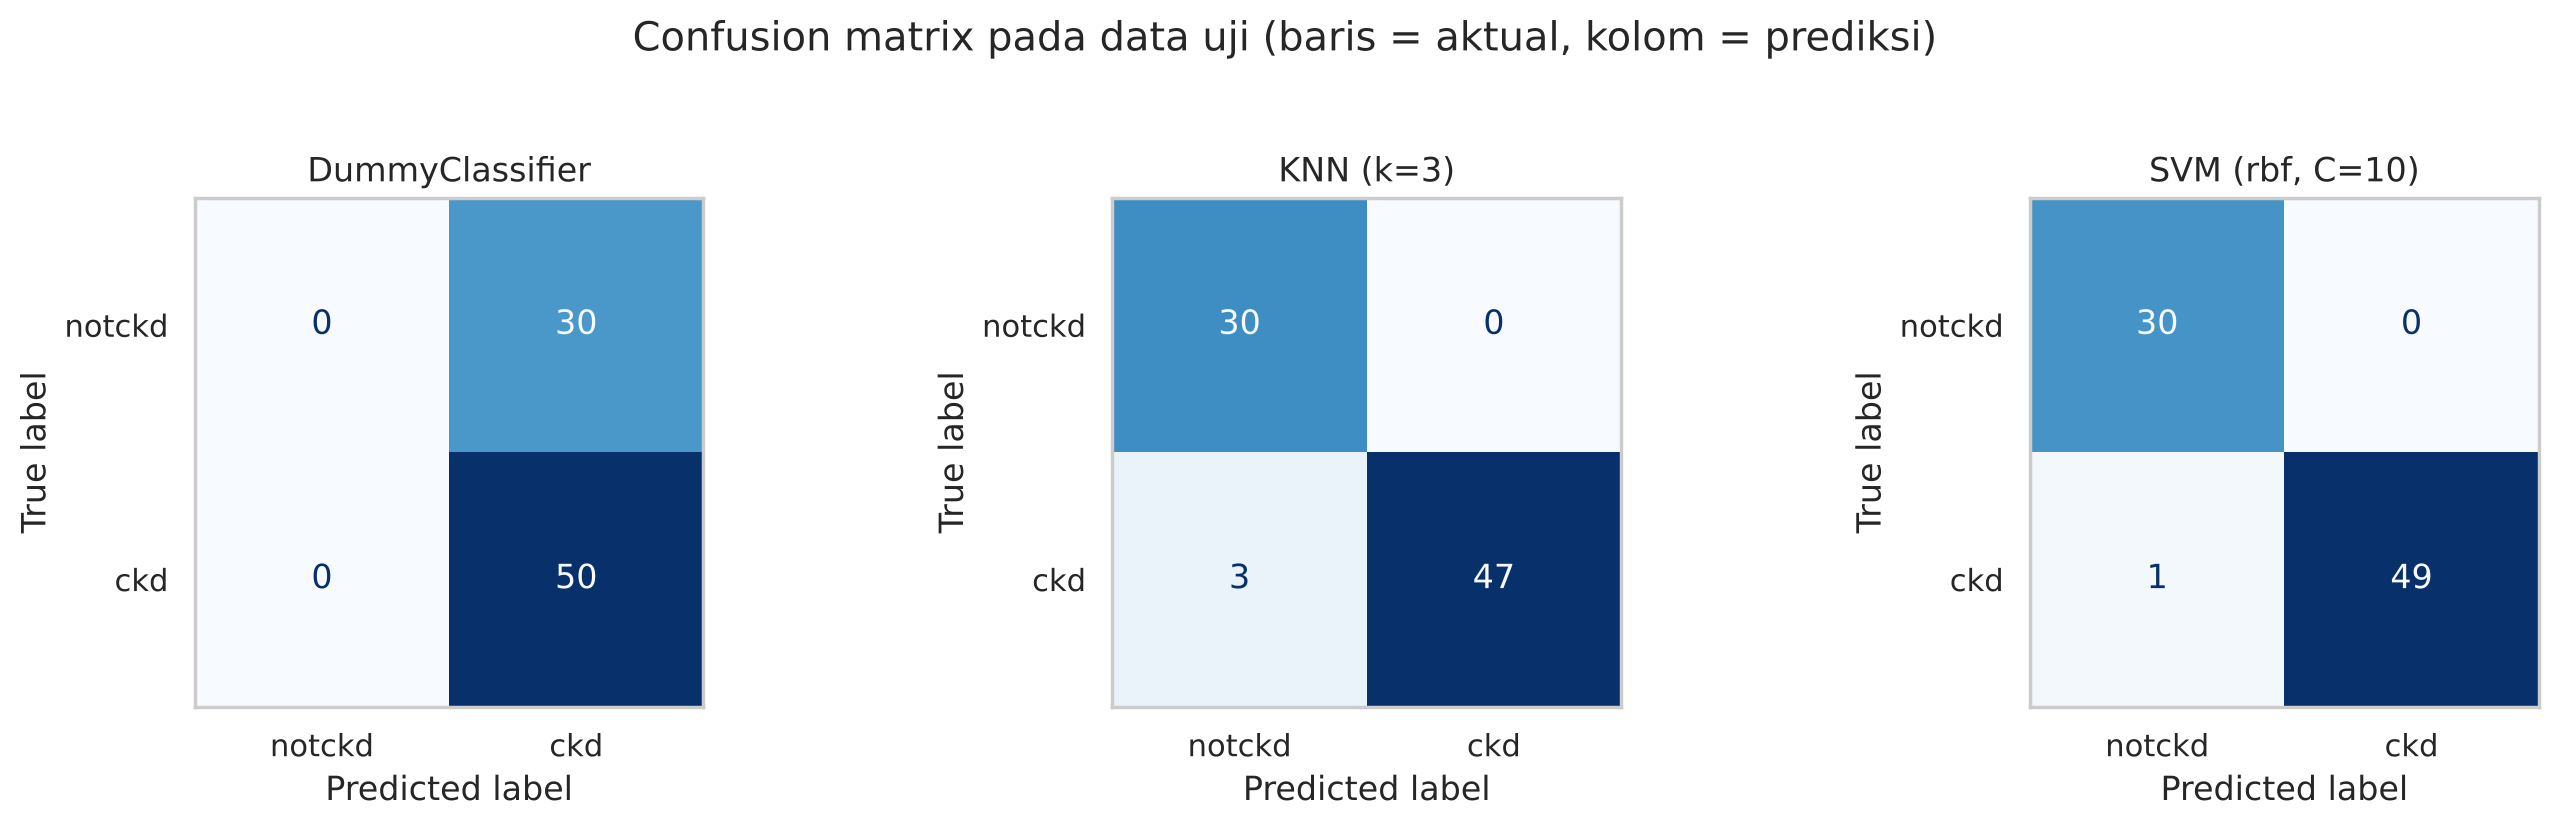

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (nama, pred) in zip(axes, prediksi.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, labels=[0, 1], display_labels=["notckd", "ckd"], cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(nama); ax.grid(False)
plt.suptitle("Confusion matrix pada data uji (baris = aktual, kolom = prediksi)", y=1.03)
plt.tight_layout(); plt.show()

### 5.2 Perhitungan manual dari angka confusion matrix (model KNN)

In [24]:
nama_knn = f"KNN (k={k_terpilih})"
tn, fp, fn, tp = confusion_matrix(y_test, prediksi[nama_knn], labels=[0, 1]).ravel()
print(f"TN = {tn}, FP = {fp}, FN = {fn}, TP = {tp}   (kelas positif = ckd)\n")

akurasi_manual = (tp + tn) / (tp + tn + fp + fn)
presisi_manual = tp / (tp + fp)
recall_manual  = tp / (tp + fn)
f1_manual      = 2 * presisi_manual * recall_manual / (presisi_manual + recall_manual)

print(f"Akurasi = (TP + TN) / total = ({tp} + {tn}) / {tp+tn+fp+fn} = {akurasi_manual:.4f}")
print(f"Presisi = TP / (TP + FP)    = {tp} / ({tp} + {fp}) = {presisi_manual:.4f}")
print(f"Recall  = TP / (TP + FN)    = {tp} / ({tp} + {fn}) = {recall_manual:.4f}")
print(f"F1      = 2*P*R / (P + R)   = {f1_manual:.4f}")

# Pemeriksaan: harus sama dengan hasil scikit-learn
pred = prediksi[nama_knn]
assert np.isclose(akurasi_manual, accuracy_score(y_test, pred))
assert np.isclose(presisi_manual, precision_score(y_test, pred))
assert np.isclose(recall_manual, recall_score(y_test, pred))
assert np.isclose(f1_manual, f1_score(y_test, pred))
print("\nSemua hitungan manual sama dengan hasil scikit-learn.")

TN = 30, FP = 0, FN = 3, TP = 47   (kelas positif = ckd)

Akurasi = (TP + TN) / total = (47 + 30) / 80 = 0.9625
Presisi = TP / (TP + FP)    = 47 / (47 + 0) = 1.0000
Recall  = TP / (TP + FN)    = 47 / (47 + 3) = 0.9400
F1      = 2*P*R / (P + R)   = 0.9691

Semua hitungan manual sama dengan hasil scikit-learn.


### 5.3 Laporan klasifikasi per kelas dan perbandingan dengan skor CV

In [25]:
for nama in list(prediksi)[1:]:
    print("=" * 60); print(nama)
    print(classification_report(y_test, prediksi[nama], target_names=["notckd", "ckd"], digits=4))

perbandingan = pd.DataFrame({
    "Akurasi CV (latih)": ringkasan_cv["accuracy"].values,
    "Akurasi uji": tabel_uji["Akurasi uji"].values,
}, index=tabel_uji.index)
perbandingan["Selisih (uji - CV)"] = perbandingan["Akurasi uji"] - perbandingan["Akurasi CV (latih)"]
perbandingan.round(4)

KNN (k=3)
              precision    recall  f1-score   support

      notckd     0.9091    1.0000    0.9524        30
         ckd     1.0000    0.9400    0.9691        50

    accuracy                         0.9625        80
   macro avg     0.9545    0.9700    0.9607        80
weighted avg     0.9659    0.9625    0.9628        80

SVM (rbf, C=10)
              precision    recall  f1-score   support

      notckd     0.9677    1.0000    0.9836        30
         ckd     1.0000    0.9800    0.9899        50

    accuracy                         0.9875        80
   macro avg     0.9839    0.9900    0.9868        80
weighted avg     0.9879    0.9875    0.9875        80



,Akurasi CV (latih),Akurasi uji,Selisih (uji - CV)
Model,,,
DummyClassifier,0.6250,0.6250,0.0000
KNN (k=3),0.9625,0.9625,0.0000
"SVM (rbf, C=10)",0.9906,0.9875,-0.0031


### Perhitungan manual (dari confusion matrix KNN, k = 3)

Dari confusion matrix: TN = 30, FP = 0, FN = 3, TP = 47 (kelas positif = `ckd`).

- Akurasi = (TP + TN) / total = (47 + 30) / 80 = 77 / 80 = **0,9625**
- Presisi = TP / (TP + FP) = 47 / (47 + 0) = **1,0000**
- Recall = TP / (TP + FN) = 47 / (47 + 3) = 47 / 50 = **0,9400**
- F1 = 2 x presisi x recall / (presisi + recall) = 2 x 1,0 x 0,94 / (1,0 + 0,94) = 1,88 / 1,94 = **0,9691**

Keempat angka sama dengan hasil scikit-learn (dibuktikan dengan `assert` pada sel di atas).

### Interpretasi hasil data uji

| Model | Akurasi uji | Presisi (ckd) | Recall (ckd) | F1 (ckd) | Pasien ckd terlewat (FN) |
|---|---|---|---|---|---|
| DummyClassifier | 62,50% | 62,50% | 100% | 76,92% | 0 (menebak semua `ckd`; 30 pasien sehat salah dicap sakit) |
| KNN (k = 3) | 96,25% | 100% | 94,00% | 96,91% | 3 dari 50 |
| SVM (rbf, C = 10) | 98,75% | 100% | 98,00% | 98,99% | 1 dari 50 |

- **Dibanding baseline.** KNN unggul 33,75 poin persentase dan SVM 36,25 poin persentase atas akurasi baseline (62,5%). Baseline tampak memiliki recall 100% hanya karena menebak semua pasien sebagai `ckd`; presisinya 62,5% dan ia tidak membedakan apa pun.
- **Jenis kesalahan.** Baik KNN maupun SVM tidak punya *false positive* (tidak ada pasien sehat yang dicap sakit). Seluruh kesalahan adalah *false negative*: 3 pasien `ckd` terlewat oleh KNN dan 1 oleh SVM. Dalam konteks skrining ini arah kesalahannya yang paling merugikan, sehingga recall menjadi metrik yang paling saya perhatikan.
- **Overfitting.** Akurasi latih KNN 99,69% vs uji 96,25% (selisih 3,44 poin); SVM 100% vs 98,75% (selisih 1,25 poin). Selisih keduanya kecil, jadi tidak ada overfitting berat, hanya sedikit lebih tinggi di KNN. Skor uji juga dekat dengan skor CV (KNN 96,25% vs 96,25%; SVM 98,75% vs 99,06%), yang menunjukkan hasilnya konsisten.
- **Kehati-hatian membaca angka.** Data uji hanya 80 pasien, jadi satu pasien yang salah ditebak setara 1,25 poin akurasi. Selisih KNN dan SVM di data uji hanya 2 pasien; namun skor CV pada 320 pasien latih (96,25% vs 99,06%) menunjukkan arah yang sama, sehingga kesimpulan bahwa SVM sedikit lebih baik cukup beralasan, bukan kebetulan satu pembagian data.

### Keputusan saya (Tahap 5)

Saya menguji tiap model **satu kali** pada data uji setelah semua pilihan (k, kernel, C) ditetapkan lewat CV di data latih, sehingga data uji tidak ikut menentukan model. Saya menilai model terutama dengan **recall kelas `ckd`** dan presisi, bukan akurasi saja, karena kesalahan yang berbahaya adalah pasien sakit yang terlewat. Keduanya mengalahkan baseline dengan selisih sangat besar, dan SVM lebih baik daripada KNN pada akurasi, recall, dan F1. Akurasi yang sangat tinggi ini tidak otomatis berarti model akan sebaik itu di rumah sakit lain; saya bahas di keterbatasan.

# 6. Kesimpulan

**Apakah model layak dipakai dibanding baseline?** Ya. Pada data uji, DummyClassifier hanya mencapai akurasi 62,50%, sedangkan KNN (k = 3) mencapai 96,25% dan SVM (rbf, C = 10) 98,75%. Pada cross-validation 5-fold di data latih, keduanya juga jauh di atas baseline (62,50%): KNN 96,25% dan SVM 99,06%.

**Model yang dipilih: SVM (kernel rbf, C = 10).** Alasannya:
1. Skor CV dan skor uji lebih tinggi daripada KNN: akurasi CV 99,06% vs 96,25%, akurasi uji 98,75% vs 96,25%.
2. Recall kelas `ckd` lebih tinggi: 98% vs 94%. SVM hanya melewatkan 1 dari 50 pasien `ckd`, sedangkan KNN melewatkan 3 dari 50, dan keduanya tidak salah menandai pasien sehat (presisi 100%).
3. Selisih akurasi latih dan uji kecil (1,25 poin untuk SVM, 3,44 poin untuk KNN), jadi tidak ada tanda overfitting berat.

KNN (k = 3) tetap layak sebagai model yang lebih mudah dijelaskan, tetapi untuk tujuan skrining, SVM lebih aman karena lebih sedikit pasien sakit yang terlewat.

**Rekomendasi tindakan bagi pengguna (tenaga kesehatan).**
- Pakai model sebagai **alat bantu penapisan awal**: pasien yang diprediksi `ckd` diprioritaskan untuk pemeriksaan lanjutan dan rujukan ke dokter. Keputusan diagnosis tetap ada pada dokter.
- Karena recall belum 100%, pasien yang diprediksi `notckd` namun punya faktor risiko atau gejala (misalnya hipertensi, diabetes, edema, nafsu makan buruk) **tetap perlu dipantau**, jangan dilepas begitu saja.
- Usahakan pemeriksaan laboratorium lengkap (misalnya kreatinin, urea, hemoglobin, albumin urin), karena fitur-fitur yang pada eksplorasi paling memisahkan kedua kelas adalah hasil laboratorium tersebut, dan data yang banyak kosong menyulitkan model.

**Keterbatasan.**
- Data hanya 400 pasien dari satu rumah sakit pada satu periode, jadi hasilnya belum tentu berlaku pada populasi atau rumah sakit lain.
- Data uji hanya 80 pasien; satu pasien setara 1,25 poin akurasi sehingga selisih antarmodel yang kecil perlu dibaca hati-hati.
- Nilai kosong jauh lebih banyak pada kelas `ckd` (27-57% pada kolom tertentu) daripada `notckd` (3-6%). Pola ini kemungkinan artefak pengumpulan data, bukan kondisi medis. Saya tidak memakainya sebagai fitur, tetapi imputasi median/modus tetap bisa memengaruhi hasil.
- Dataset ini relatif mudah dipisahkan (banyak fitur laboratorium yang sangat jelas bedanya), sehingga akurasi setinggi ini belum tentu terulang pada kasus yang lebih samar (misalnya CKD stadium sangat awal).

**Saran perbaikan.**
- Uji model pada data dari rumah sakit lain (validasi eksternal) dan gunakan cross-validation berulang atau interval kepercayaan agar angka lebih stabil.
- Bandingkan dengan algoritma lain seperti regresi logistik atau Random Forest, dan coba imputasi yang lebih canggih (misalnya `KNNImputer`) di dalam `Pipeline`.
- Atur ambang keputusan agar recall `ckd` lebih diutamakan, dan periksa kalibrasi probabilitas sebelum model dipakai untuk menentukan prioritas pasien.